## Difference between random and noise

First, let's get into one dimensional Perlin Noise. Let's imagine that, over time, we will choose a random number and write it down:

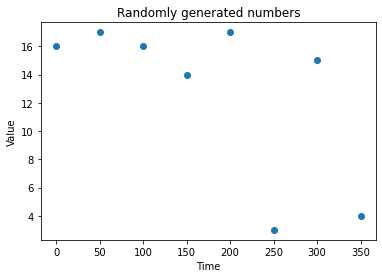

In [1]:
from random import randint

import matplotlib.pylab as plt

tamanho = 400
intervalo, amplitude = 50, 20

y = [randint(1, amplitude) for _ in range(0, tamanho, intervalo)]
x = [_ for _ in range(0, tamanho, intervalo)]

plt.title('Randomly generated numbers')
plt.ylabel('Value')
plt.xlabel('Time')

plt.scatter(x, y)
plt.show()

If we connect these points, we will have the following:

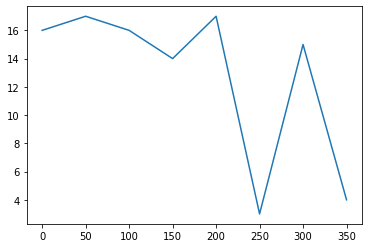

In [2]:
plt.plot(x, y)
plt.show()

As you can see, this graph does not look natural or organic when using linear interpolation to connect the points.
But how about the next one?

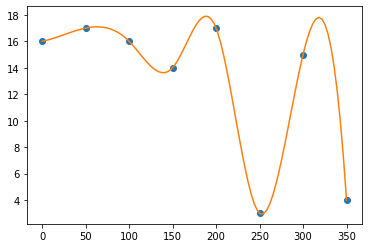

In [3]:
from scipy.interpolate import interp1d

import numpy as np

f = interp1d(x, y, kind='cubic')

x_new = np.linspace(0, x[-1], num=100, endpoint=True)
plt.plot(
    x, y, 'o',
    x_new, f(x_new), '-'
)
plt.show()

This smooth graph is plotting a matrix of one octave Perlin noise values. And what is this “octave”?

As we decrease by half the time interval and the amplitude for this randomness, we create a new octave.

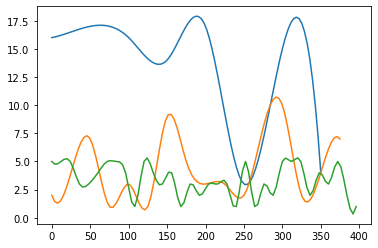

In [4]:
intervalo, amplitude = 25, 10

y2 = [randint(1, amplitude) for _ in range(0, tamanho, intervalo)]
x2 = [_ for _ in range(0, tamanho, intervalo)]

intervalo, amplitude = 12, 5

y3 = [randint(1, amplitude) for _ in range(0, tamanho, intervalo)]
x3 = [_ for _ in range(0, tamanho, intervalo)]

f2 = interp1d(x2, y2, kind='cubic')
f3 = interp1d(x3, y3, kind='cubic')

x_new2 = np.linspace(0, x2[-1], num=100, endpoint=True)
x_new3 = np.linspace(0, x3[-1], num=100, endpoint=True)

plt.plot(
    x_new, f(x_new), '-',
    x_new2, f2(x_new2), '-',
    x_new3, f3(x_new3), '-'
)
plt.show()

The overlapping of the octaves generates a one-dimensional set of Perlin noise values.

---

## Tests

[0.0, 0.00027987224114093027, 0.0005597451993132361, 0.0008396195879144426, 0.001119496116384057, 0.0013993754902103545, 0.0016792584109371603, 0.001959145576170641, 0.002239037679586056, 0.0025189354109345636, 0.002798839456049954, 0.003078750496855435, 0.0033586692113703764, 0.0036385962737170807, 0.003918532354127507, 0.004198478118950063, 0.00447843423065627, 0.004758401347847585, 0.005038380125262076, 0.005318371213781172, 0.005598375260436368, 0.005878392908415966, 0.006158424797071809, 0.0064384715619259306, 0.006718533834677303, 0.006998612243208524, 0.007278707411592569, 0.007558819960099412, 0.00783895050520266, 0.008119099659586484, 0.008399268032152001, 0.008679456228024124, 0.008959664848558244, 0.00923989449134672, 0.00952014575022583, 0.009800419215282102, 0.010080715472859277, 0.010361035105564756, 0.010641378692276266, 0.010921746808148655, 0.011202140024620248, 0.01148255890941988, 0.011763004026573022, 0.01204347593640882, 0.012323975195566694, 0.012604502357002582, 

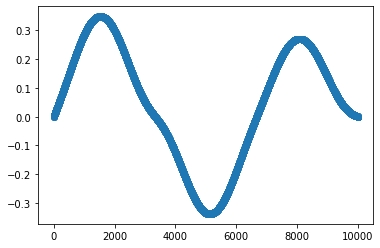

In [5]:
from perlin_noise import PerlinNoise

noise = PerlinNoise(octaves=3, seed=1234)

x_pix = 10000

y = [noise(i / x_pix) for i in range(x_pix)]
x = [_ for _ in range(len(y))]

print(y)

plt.scatter(x, y)
plt.show()